<a href="https://colab.research.google.com/github/syayalaherrera-beep/Algoritmos-de-Clasificaci-n/blob/main/Algoritmos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Introducción

El Machine Learning es una rama de la inteligencia artificial que permite desarrollar modelos capaces de identificar patrones en los datos y realizar predicciones a partir de ejemplos previamente clasificados. Dentro de este campo, los algoritmos de clasificación supervisada se utilizan para asignar observaciones a categorías definidas, de acuerdo con las características de entrada y los patrones aprendidos durante el entrenamiento.

En esta actividad se implementan y comparan cinco algoritmos de clasificación: Árbol de Decisión (*Decision Tree*), Bosque Aleatorio (*Random Forest*), Máquina de Vectores de Soporte (*Support Vector Machine*, SVM), K vecinos más cercanos (*K-Nearest Neighbors*, K-NN) y Naive Bayes. Para desarrollar el ejercicio se utiliza el conjunto de datos *Breast Cancer Wisconsin Diagnostic*, disponible en la biblioteca Scikit-learn, que contiene mediciones numéricas asociadas con muestras clasificadas como benignas o malignas.

El desarrollo comprende la identificación de las variables de entrada y la variable objetivo, la preparación y división de los datos, el entrenamiento de los modelos y la generación de predicciones. Para garantizar una comparación consistente, todos los algoritmos utilizan la misma partición de entrenamiento y prueba. Su desempeño se evalúa mediante las métricas Accuracy, Precision, Recall y F1-score, complementadas con matrices de confusión que permiten identificar los aciertos y los errores de clasificación.

Finalmente, los resultados obtenidos se analizan comparativamente para establecer las fortalezas y limitaciones de cada algoritmo y justificar la selección de un modelo de acuerdo con su desempeño. El ejercicio tiene fines exclusivamente académicos.

# 2. Objetivo general

Implementar y comparar cinco algoritmos de clasificación supervisada mediante Python y Scikit-learn, utilizando el conjunto de datos *Breast Cancer Wisconsin Diagnostic*, con el propósito de evaluar su desempeño a través de métricas de clasificación y matrices de confusión, interpretar sus resultados y justificar la selección del modelo más adecuado para el problema planteado.

### 3.1. Objetivos específicos

1. Identificar las variables de entrada y la variable objetivo del conjunto de datos, estableciendo la codificación de las clases benigna y maligna.

2. Preparar los datos y establecer una división común de entrenamiento y prueba que permita comparar los cinco algoritmos bajo las mismas condiciones.

3. Implementar los algoritmos Decision Tree, Random Forest, SVM, K-NN y Naive Bayes, aplicando los procedimientos de escalamiento requeridos por los modelos sensibles a la magnitud de las variables.

4. Evaluar el desempeño de cada clasificador mediante Accuracy, Precision, Recall, F1-score y matrices de confusión.

5. Comparar e interpretar los resultados obtenidos, identificando los falsos positivos, los falsos negativos y las diferencias de desempeño entre los modelos.

6. Justificar la selección del modelo final a partir de las métricas obtenidas, la capacidad de detectar casos malignos y las características de cada algoritmo.

In [4]:

# Semana 8 - Algoritmos de clasificación
# Autora: Sandra Yurani Ayala Herrera
# Universidad de Cundinamarca - CADI
# Objetivo: comparar cinco algoritmos de clasificación.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Cargar el conjunto de datos en un DataFrame
data = load_breast_cancer(as_frame=True)

# Variables de entrada
X = data.data.copy()

# Variable objetivo: 1 = maligno, 0 = benigno
y = (data.target == 0).astype(int)

# Inspeccionar las dimensiones y las primeras filas
print("Dimensiones de X:", X.shape)
print("\nPrimeras cinco observaciones:")
display(X.head())

# Revisar la distribución de las clases
print("\nDistribución de la variable objetivo:")
print(y.value_counts().sort_index())

print("\nProporción de cada clase:")
print(y.value_counts(normalize=True).sort_index().round(3))


Dimensiones de X: (569, 30)

Primeras cinco observaciones:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Distribución de la variable objetivo:
target
0    357
1    212
Name: count, dtype: int64

Proporción de cada clase:
target
0    0.627
1    0.373
Name: proportion, dtype: float64


In [5]:
# Dividir los datos en entrenamiento y prueba.
# Todos los modelos utilizarán exactamente esta misma división.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verificar las dimensiones de cada partición
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nDistribución de clases en prueba:")
print(y_test.value_counts().sort_index())

Datos de entrenamiento: (455, 30)
Datos de prueba: (114, 30)

Distribución de clases en entrenamiento:
target
0    285
1    170
Name: count, dtype: int64

Distribución de clases en prueba:
target
0    72
1    42
Name: count, dtype: int64


RESULTADOS DEL ÁRBOL DE DECISIÓN
Accuracy:  0.9123
Precision: 0.9444
Recall:    0.8095
F1-score:  0.8718

Matriz de confusión:
[[70  2]
 [ 8 34]]


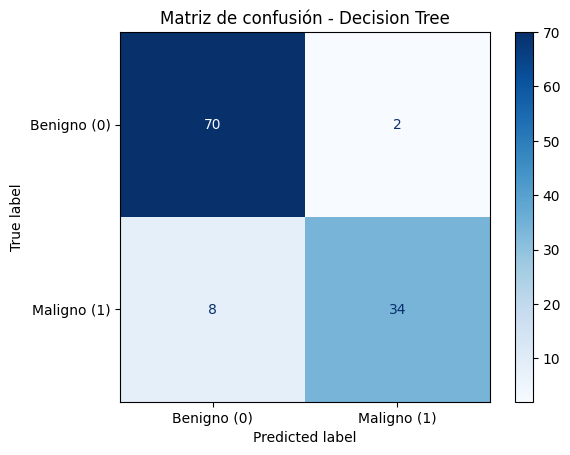

In [6]:

# EJERCICIO 2: ÁRBOL DE DECISIÓN (DECISION TREE)

# Importar el algoritmo y las métricas de evaluación
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Crear el modelo con profundidad máxima de 4
# Esta restricción ayuda a controlar la complejidad del árbol
modelo_dt = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Entrenar el modelo con los datos de entrenamiento
modelo_dt.fit(X_train, y_train)

# Predecir las clases de los datos de prueba
y_pred_dt = modelo_dt.predict(X_test)

# Calcular las métricas de evaluación
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)

# Mostrar los resultados
print("RESULTADOS DEL ÁRBOL DE DECISIÓN")
print(f"Accuracy:  {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall:    {recall_dt:.4f}")
print(f"F1-score:  {f1_dt:.4f}")

# Mostrar la matriz de confusión
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])

print("\nMatriz de confusión:")
print(cm_dt)

# Visualizar la matriz de confusión
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Benigno (0)", "Maligno (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Decision Tree")
plt.show()



### Análisis del modelo Decision Tree

El Árbol de Decisión obtuvo un Accuracy de 91,23 %,
Precision de 94,44 %, Recall de 80,95 % y F1-score de
87,18 %.

La matriz de confusión registró 70 verdaderos negativos,
2 falsos positivos, 8 falsos negativos y 34 verdaderos
positivos. El modelo presentó un buen desempeño general,
pero dejó de identificar 8 casos malignos reales.

La limitación principal observada fue su menor capacidad
para detectar la clase maligna frente a los otros modelos
evaluados hasta el momento.


RESULTADOS - RANDOM FOREST
Accuracy:  0.9737
Precision: 1.0000
Recall:    0.9286
F1-score:  0.9630

Matriz de confusión:
[[72  0]
 [ 3 39]]


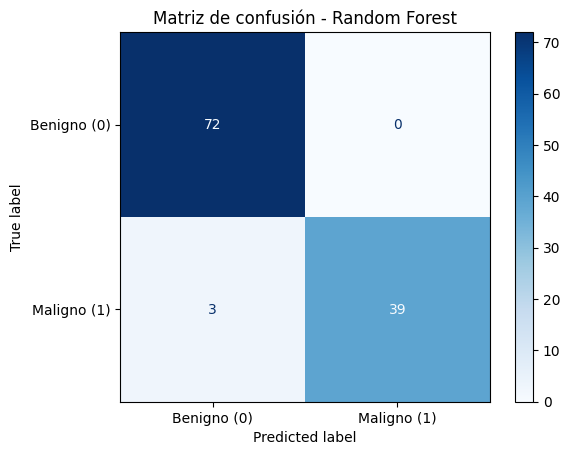

In [7]:

# EJERCICIO 3: RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Crear un conjunto de 100 árboles de decisión
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Entrenar con la misma partición de datos
modelo_rf.fit(X_train, y_train)

# Predecir los diagnósticos del conjunto de prueba
y_pred_rf = modelo_rf.predict(X_test)

# Calcular las métricas
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

print("RESULTADOS - RANDOM FOREST")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")

# Matriz de confusión
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
print("\nMatriz de confusión:")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Benigno (0)", "Maligno (1)"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Random Forest")
plt.show()



### Análisis del modelo Random Forest

Random Forest obtuvo un Accuracy de 97,37 %, Precision
de 100 %, Recall de 92,86 % y F1-score de 96,30 %.

La matriz de confusión mostró 72 verdaderos negativos,
0 falsos positivos, 3 falsos negativos y 39 verdaderos
positivos. En comparación con Decision Tree, mejoró
todas las métricas y redujo los falsos negativos de 8 a 3.

En esta evaluación, Random Forest presentó uno de los
mejores desempeños, aunque su resultado debe compararse
con los demás algoritmos antes de seleccionar el modelo.


RESULTADOS - SVM
Accuracy:  0.9737
Precision: 1.0000
Recall:    0.9286
F1-score:  0.9630

Matriz de confusión:
[[72  0]
 [ 3 39]]


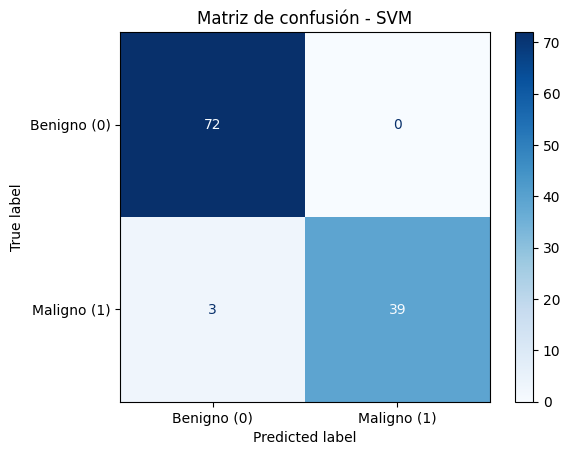

In [8]:

# EJERCICIO 4: SUPPORT VECTOR MACHINE (SVM)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Crear el pipeline: estandarización y clasificador SVM
modelo_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

# Entrenar con la misma partición utilizada anteriormente
modelo_svm.fit(X_train, y_train)

# Predecir las clases del conjunto de prueba
y_pred_svm = modelo_svm.predict(X_test)

# Calcular las métricas con maligno (1) como clase positiva
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, zero_division=0)
recall_svm = recall_score(y_test, y_pred_svm, zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, zero_division=0)

print("RESULTADOS - SVM")
print(f"Accuracy:  {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall:    {recall_svm:.4f}")
print(f"F1-score:  {f1_svm:.4f}")

# Generar la matriz de confusión
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1])
print("\nMatriz de confusión:")
print(cm_svm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Benigno (0)", "Maligno (1)"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión - SVM")
plt.show()


# Análisis del algoritmo Support Vector Machine (SVM)

SVM obtuvo un Accuracy de 97,37 %, Precision de 100 %,
Recall de 92,86 % y F1-score de 96,30 %.

Su matriz de confusión registró 72 verdaderos negativos,
0 falsos positivos, 3 falsos negativos y 39 verdaderos
positivos. Los resultados coincidieron con los obtenidos
por Random Forest en esta partición de los datos.

Ambos modelos lideran las métricas evaluadas. No obstante,
la igualdad de resultados en esta prueba no demuestra que
tengan el mismo comportamiento en otros conjuntos de datos.

RESULTADOS - K-NN
Accuracy:  0.9561
Precision: 0.9744
Recall:    0.9048
F1-score:  0.9383

Matriz de confusión:
[[71  1]
 [ 4 38]]


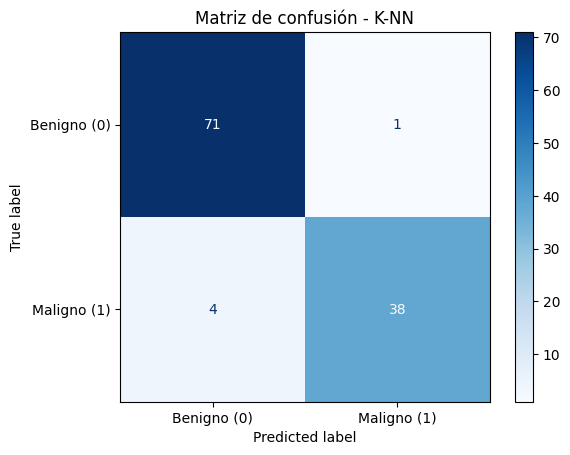

In [9]:

# EJERCICIO 5: K-NEAREST NEIGHBORS (K-NN)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Estandarizar los datos y clasificar usando los 5 vecinos más cercanos
modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Entrenar con la misma partición de datos
modelo_knn.fit(X_train, y_train)

# Predecir las clases del conjunto de prueba
y_pred_knn = modelo_knn.predict(X_test)

# Calcular las métricas, considerando maligno (1) como clase positiva
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)

print("RESULTADOS - K-NN")
print(f"Accuracy:  {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall:    {recall_knn:.4f}")
print(f"F1-score:  {f1_knn:.4f}")

# Matriz de confusión
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])
print("\nMatriz de confusión:")
print(cm_knn)

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Benigno (0)", "Maligno (1)"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión - K-NN")
plt.show()


# Análisis del modelo K-Nearest Neighbors (K-NN)

K-NN obtuvo un Accuracy de 95,61 %, Precision de 97,44 %,
Recall de 90,48 % y F1-score de 93,83 %.

La matriz de confusión mostró 71 verdaderos negativos,
1 falso positivo, 4 falsos negativos y 38 verdaderos
positivos. Clasificó correctamente 109 de los 114 casos.

Aunque presentó buenos resultados, detectó un caso maligno
menos que Random Forest y SVM, y produjo un falso positivo.

RESULTADOS - NAIVE BAYES
Accuracy:  0.9386
Precision: 1.0000
Recall:    0.8333
F1-score:  0.9091

Matriz de confusión:
[[72  0]
 [ 7 35]]


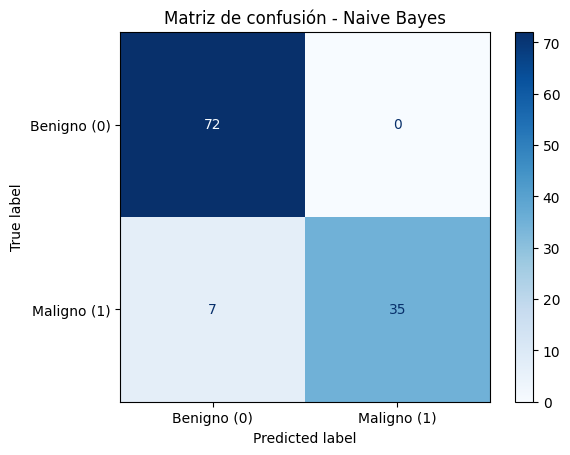

In [10]:

# EJERCICIO 6: NAIVE BAYES

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Crear el modelo Gaussian Naive Bayes
modelo_nb = GaussianNB()

# Entrenar con la misma partición de datos
modelo_nb.fit(X_train, y_train)

# Predecir las clases del conjunto de prueba
y_pred_nb = modelo_nb.predict(X_test)

# Calcular las métricas, usando maligno (1) como clase positiva
accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb, zero_division=0)
recall_nb = recall_score(y_test, y_pred_nb, zero_division=0)
f1_nb = f1_score(y_test, y_pred_nb, zero_division=0)

print("RESULTADOS - NAIVE BAYES")
print(f"Accuracy:  {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print(f"Recall:    {recall_nb:.4f}")
print(f"F1-score:  {f1_nb:.4f}")

# Mostrar la matriz de confusión
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=[0, 1])
print("\nMatriz de confusión:")
print(cm_nb)

ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Benigno (0)", "Maligno (1)"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Naive Bayes")
plt.show()


# Análisis del modelo Naive Bayes

Naive Bayes obtuvo un Accuracy de 93,86 %, Precision
de 100 %, Recall de 83,33 % y F1-score de 90,91 %.

La matriz de confusión registró 72 verdaderos negativos,
0 falsos positivos, 7 falsos negativos y 35 verdaderos
positivos. Aunque todas las predicciones de malignidad
fueron correctas, el modelo dejó de detectar 7 casos
malignos reales.

Por ello, la Precision de 100 % debe interpretarse junto
con el Recall: el modelo fue preciso al predecir malignidad,
pero no identificó una proporción tan alta de los casos
malignos reales como Random Forest o SVM.

In [11]:

# EJERCICIO 7: COMPARACIÓN FINAL DE LOS CINCO MODELOS

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)
import pandas as pd

# Asociar cada modelo con sus predicciones
modelos = {
    "Decision Tree": (modelo_dt, y_pred_dt),
    "Random Forest": (modelo_rf, y_pred_rf),
    "SVM": (modelo_svm, y_pred_svm),
    "K-NN": (modelo_knn, y_pred_knn),
    "Naive Bayes": (modelo_nb, y_pred_nb)
}

resultados = []

for nombre, (modelo, predicciones) in modelos.items():

    # La matriz se organiza como:
    # [[verdaderos negativos, falsos positivos],
    #  [falsos negativos, verdaderos positivos]]
    tn, fp, fn, tp = confusion_matrix(
        y_test, predicciones, labels=[0, 1]
    ).ravel()

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones, zero_division=0
        ),
        "Falsos positivos": fp,
        "Falsos negativos": fn
    })

# Construir la tabla comparativa
tabla_resultados = pd.DataFrame(resultados)

# Mostrar porcentajes con dos decimales
tabla_visual = tabla_resultados.copy()
metricas = ["Accuracy", "Precision", "Recall", "F1-score"]
tabla_visual[metricas] = (
    tabla_visual[metricas] * 100
).round(2)

display(tabla_visual)

# Identificar los mejores valores de cada métrica
print("Mayor Accuracy:",
      tabla_resultados.loc[
          tabla_resultados["Accuracy"].idxmax(), "Modelo"
      ])

print("Mayor Recall:",
      tabla_resultados.loc[
          tabla_resultados["Recall"].idxmax(), "Modelo"
      ])

print("Mayor F1-score:",
      tabla_resultados.loc[
          tabla_resultados["F1-score"].idxmax(), "Modelo"
      ])


,Modelo,Accuracy,Precision,Recall,F1-score,Falsos positivos,Falsos negativos
0,Decision Tree,91.23,94.44,80.95,87.18,2,8
1,Random Forest,97.37,100.00,92.86,96.30,0,3
2,SVM,97.37,100.00,92.86,96.30,0,3
3,K-NN,95.61,97.44,90.48,93.83,1,4
4,Naive Bayes,93.86,100.00,83.33,90.91,0,7


Mayor Accuracy: Random Forest
Mayor Recall: Random Forest
Mayor F1-score: Random Forest


In [13]:

# TABLA COMPARATIVA FINAL

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

modelos = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm,
    "K-NN": y_pred_knn,
    "Naive Bayes": y_pred_nb
}

resultados = []

for nombre, pred in modelos.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    resultados.append({
        "Modelo": nombre,
        "Accuracy (%)": round(
            accuracy_score(y_test, pred) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, pred, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, pred, zero_division=0) * 100, 2
        ),
        "F1-score (%)": round(
            f1_score(y_test, pred, zero_division=0) * 100, 2
        ),
        "Falsos positivos": fp,
        "Falsos negativos": fn
    })

tabla_comparativa = pd.DataFrame(resultados)

display(tabla_comparativa)


,Modelo,Accuracy (%),Precision (%),Recall (%),F1-score (%),Falsos positivos,Falsos negativos
0,Decision Tree,91.23,94.44,80.95,87.18,2,8
1,Random Forest,97.37,100.00,92.86,96.30,0,3
2,SVM,97.37,100.00,92.86,96.30,0,3
3,K-NN,95.61,97.44,90.48,93.83,1,4
4,Naive Bayes,93.86,100.00,83.33,90.91,0,7



## Comparación y selección del modelo final

Random Forest y SVM obtuvieron los mejores resultados,
con Accuracy de 97,37 %, Precision de 100 %, Recall de
92,86 % y F1-score de 96,30 %. Ambos modelos registraron
3 falsos negativos y ningún falso positivo.

K-NN obtuvo un Accuracy de 95,61 % y un Recall de 90,48 %.
Naive Bayes alcanzó un Accuracy de 93,86 % y un Recall
de 83,33 %, mientras que Decision Tree obtuvo un Accuracy
de 91,23 % y un Recall de 80,95 %.

Se propone Random Forest como modelo final provisional,
debido a su alto desempeño y a la posibilidad de analizar
la importancia relativa de las variables. Sin embargo,
SVM obtuvo métricas idénticas, por lo que no se puede
afirmar que Random Forest sea superior en esta evaluación.

